# Experiment A — Part 3: final preprocessing order comparison

Compare three fixed conditions on the **exact same 250 IAM and 250 Bentham test lines** as Parts 1 and 2:
- baseline: no optional preprocessing
- part2_order: intensity → grayscale → denoising → deskew → CLAHE → size
- clahe_first: intensity → grayscale → CLAHE → denoising → deskew → size

All active transforms and dataset-specific parameters are frozen from Part 2, which restored the validation selections from Part 1. IAM: denoising h=7, deskew ±5°/0.5°, CLAHE clip1/grid8x8. Bentham: h=1, deskew ±10°/0.25°, CLAHE clip2/grid16x16. Both use size height128, standard grayscale and global min-max intensity normalization. No training, parameter search or further order search.

The reordered pipeline moves CLAHE before both denoising and deskew, so this evaluates the full order change, not an isolated denoising interaction. A visual reduction in background variation does not establish better recognition. Primary comparison: corpus CER of clahe_first minus part2_order; also report WER and baseline changes. Negative changes favor the revised order. The comparison is fixed before inference; do not tune it from test outcomes.

Use the same pinned checkpoint, processor, decoding, source indices, batch size and text normalization. Corpus metrics collapse whitespace and retain case/punctuation. Bentham RGBA is composited onto white for all conditions. Originals remain unchanged. These are final measurements on fixed test subsets, not the entire test partitions. Parts 1 and 2 stay unchanged.

In [3]:
from pathlib import Path
import sys
import json
import platform
import hashlib
import random
import shutil
from datetime import datetime, timezone
from importlib.metadata import version
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models import TrOCRRecognizer
from src.preprocessing import (PreprocessingPipeline, Grayscale, NonLocalMeans,
    Deskew, CLAHE, IntensityNormalization, SizeNormalization)
from src.validation.denoising import adapt_image, evaluate
from src.evaluation.recognition import corpus_metrics
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [4]:
PART1 = ROOT / "results/test/experiment_a/20261112T024202644804Z"
PART2 = ROOT / "results/test/experiment_a_part_2/20261112T030651144026Z"
reference = json.loads((PART1 / "metadata.json").read_text())
part2_reference = json.loads((PART2 / "metadata.json").read_text())
assert json.loads((PART2 / "status.json").read_text())["status"] == "complete"
assert json.loads((PART1 / "status.json").read_text())["status"] == "complete"
SPLIT, SAMPLE_COUNT = "test", 250
SEED = reference["seed"]
BATCH_SIZE = 8
DATASET_REVISION = reference["datasets"]["iam"]["revision"]
CHECKPOINT = reference["model"]["checkpoint"]
MODEL_REVISION = reference["model"]["revision"]
DEVICE = reference["model"]["device"]
GENERATION = reference["model"]["generation_kwargs"]
ORDERS = {
    "part2_order": ("intensity_normalization", "grayscale", "denoising", "deskew", "clahe", "size_normalization"),
    "clahe_first": ("intensity_normalization", "grayscale", "clahe", "denoising", "deskew", "size_normalization"),
}
assert list(ORDERS["part2_order"]) == part2_reference["preprocessing_order"]
pipelines_by_dataset, parameter_rows = {}, []
for dataset_name in ("iam", "bentham"):
    saved = reference["preprocessing"][dataset_name]
    nlm, deskew, clahe, size = [saved[name]["steps"][0] for name in ("denoising", "deskew", "clahe", "size_normalization")]
    steps = {
        "intensity_normalization": IntensityNormalization(),
        "grayscale": Grayscale(),
        "denoising": NonLocalMeans(**{key: nlm[key] for key in ("h", "h_color", "template_window_size", "search_window_size")}),
        "deskew": Deskew(max_angle=deskew["max_angle"], angle_step=deskew["angle_step"]),
        "clahe": CLAHE(clip_limit=clahe["clip_limit"], tile_grid_size=tuple(clahe["tile_grid_size"])),
        "size_normalization": SizeNormalization(target_height=size["target_height"]),
    }
    for name, step in steps.items():
        assert json.loads(json.dumps(step.to_config())) == saved[name]["steps"][0]
        parameter_rows.append({"dataset": dataset_name, "technique": name,
            "parameters": json.dumps(step.to_config())})
    pipelines_by_dataset[dataset_name] = {
        "baseline": PreprocessingPipeline(),
        **{order_name: PreprocessingPipeline(tuple(steps[name] for name in order)) for order_name, order in ORDERS.items()},
    }
pipeline_names = ["baseline", "part2_order", "clahe_first"]
for dataset_name in ("iam", "bentham"):
    assert json.loads(json.dumps(pipelines_by_dataset[dataset_name]["part2_order"].to_config())) == part2_reference["preprocessing"][dataset_name]["combined"]
    assert sorted(json.dumps(s.to_config(), sort_keys=True) for s in pipelines_by_dataset[dataset_name]["part2_order"].steps) == sorted(json.dumps(s.to_config(), sort_keys=True) for s in pipelines_by_dataset[dataset_name]["clahe_first"].steps)
assert reference["sample_indices"] == part2_reference["sample_indices"] and reference["model"] == part2_reference["model"]
frozen_config = {dataset_name: {name: pipe.to_config() for name, pipe in pipes.items()}
                 for dataset_name, pipes in pipelines_by_dataset.items()}
config_digest = hashlib.sha256(json.dumps(frozen_config, sort_keys=True).encode()).hexdigest()
assert reference["split"] == SPLIT and reference["sample_count_per_dataset"] == SAMPLE_COUNT
assert reference["datasets"]["bentham"]["revision"] == REVISION
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Fixed orders:", ORDERS)
display(pd.DataFrame(parameter_rows))
print("Frozen configuration SHA-256:", config_digest)

Fixed orders: {'part2_order': ('intensity_normalization', 'grayscale', 'denoising', 'deskew', 'clahe', 'size_normalization'), 'clahe_first': ('intensity_normalization', 'grayscale', 'clahe', 'denoising', 'deskew', 'size_normalization')}


,dataset,technique,parameters
0,iam,intensity_normalization,"{""name"": ""intensity_normalization"", ""enabled"":..."
1,iam,grayscale,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
2,iam,denoising,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
3,iam,deskew,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."
4,iam,clahe,"{""name"": ""clahe"", ""enabled"": true, ""clip_limit..."
5,iam,size_normalization,"{""name"": ""size_normalization"", ""enabled"": true..."
6,bentham,intensity_normalization,"{""name"": ""intensity_normalization"", ""enabled"":..."
7,bentham,grayscale,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
8,bentham,denoising,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
9,bentham,deskew,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."


Frozen configuration SHA-256: 8b1303bb3c30b322f668d56bb277d0a5f5e09e6b1594d00196068a52541e1699


In [5]:
datasets = {"iam": load_iam_dataset(split=SPLIT, revision=DATASET_REVISION),
            "bentham": load_bentham_dataset(split=SPLIT)}
indices_by_dataset = reference["sample_indices"]
selected, samples_by_dataset, sample_rows = {}, {}, []
for dataset_name, dataset in datasets.items():
    assert dataset._fingerprint == reference["datasets"][dataset_name]["fingerprint"]
    indices = indices_by_dataset[dataset_name]
    assert len(indices) == len(set(indices)) == 250
    subset = dataset.select(indices)
    if dataset_name == "iam":
        subset = subset.add_column("id", [f"sample_{i}" for i in indices])
    assert subset._fingerprint == reference["datasets"][dataset_name]["selected_fingerprint"]
    selected[dataset_name] = subset
    samples = []
    for index, row in zip(indices, subset):
        assert isinstance(row["text"], str) and row["text"].strip()
        image = adapt_image(row["image"])
        sample = {"id": row["id"], "image": image, "ground_truth": row["text"]}
        samples.append(sample)
        sample_rows.append({"dataset": dataset_name, "sample_id": row["id"],
            "dataset_index": index, "source_mode": row["image"].mode, "mode": image.mode,
            "width": image.width, "height": image.height, "ground_truth": row["text"]})
    assert len({s["id"] for s in samples}) == 250
    samples_by_dataset[dataset_name] = samples
sample_info = pd.DataFrame(sample_rows)
print("Test split sizes:", {name: len(ds) for name, ds in datasets.items()})
display(sample_info.groupby(["dataset", "source_mode", "mode"]).size().rename("selected_lines").to_frame())
display(sample_info.groupby("dataset").head(2))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Test split sizes: {'iam': 2915, 'bentham': 860}


,,,selected_lines
dataset,source_mode,mode,
bentham,RGBA,RGB,250
iam,L,L,250


,dataset,sample_id,dataset_index,source_mode,mode,width,height,ground_truth
0,iam,sample_11,11,L,L,959,128,round a doll's house .
1,iam,sample_18,18,L,L,2209,128,such as a chair and a motor-car . The idea is ...
250,bentham,096_028_001_01_03,2,RGBA,RGB,1573,154,in paving the way to the consideration of
251,bentham,096_028_001_01_06,5,RGBA,RGB,1607,145,much time in explaining the nature &


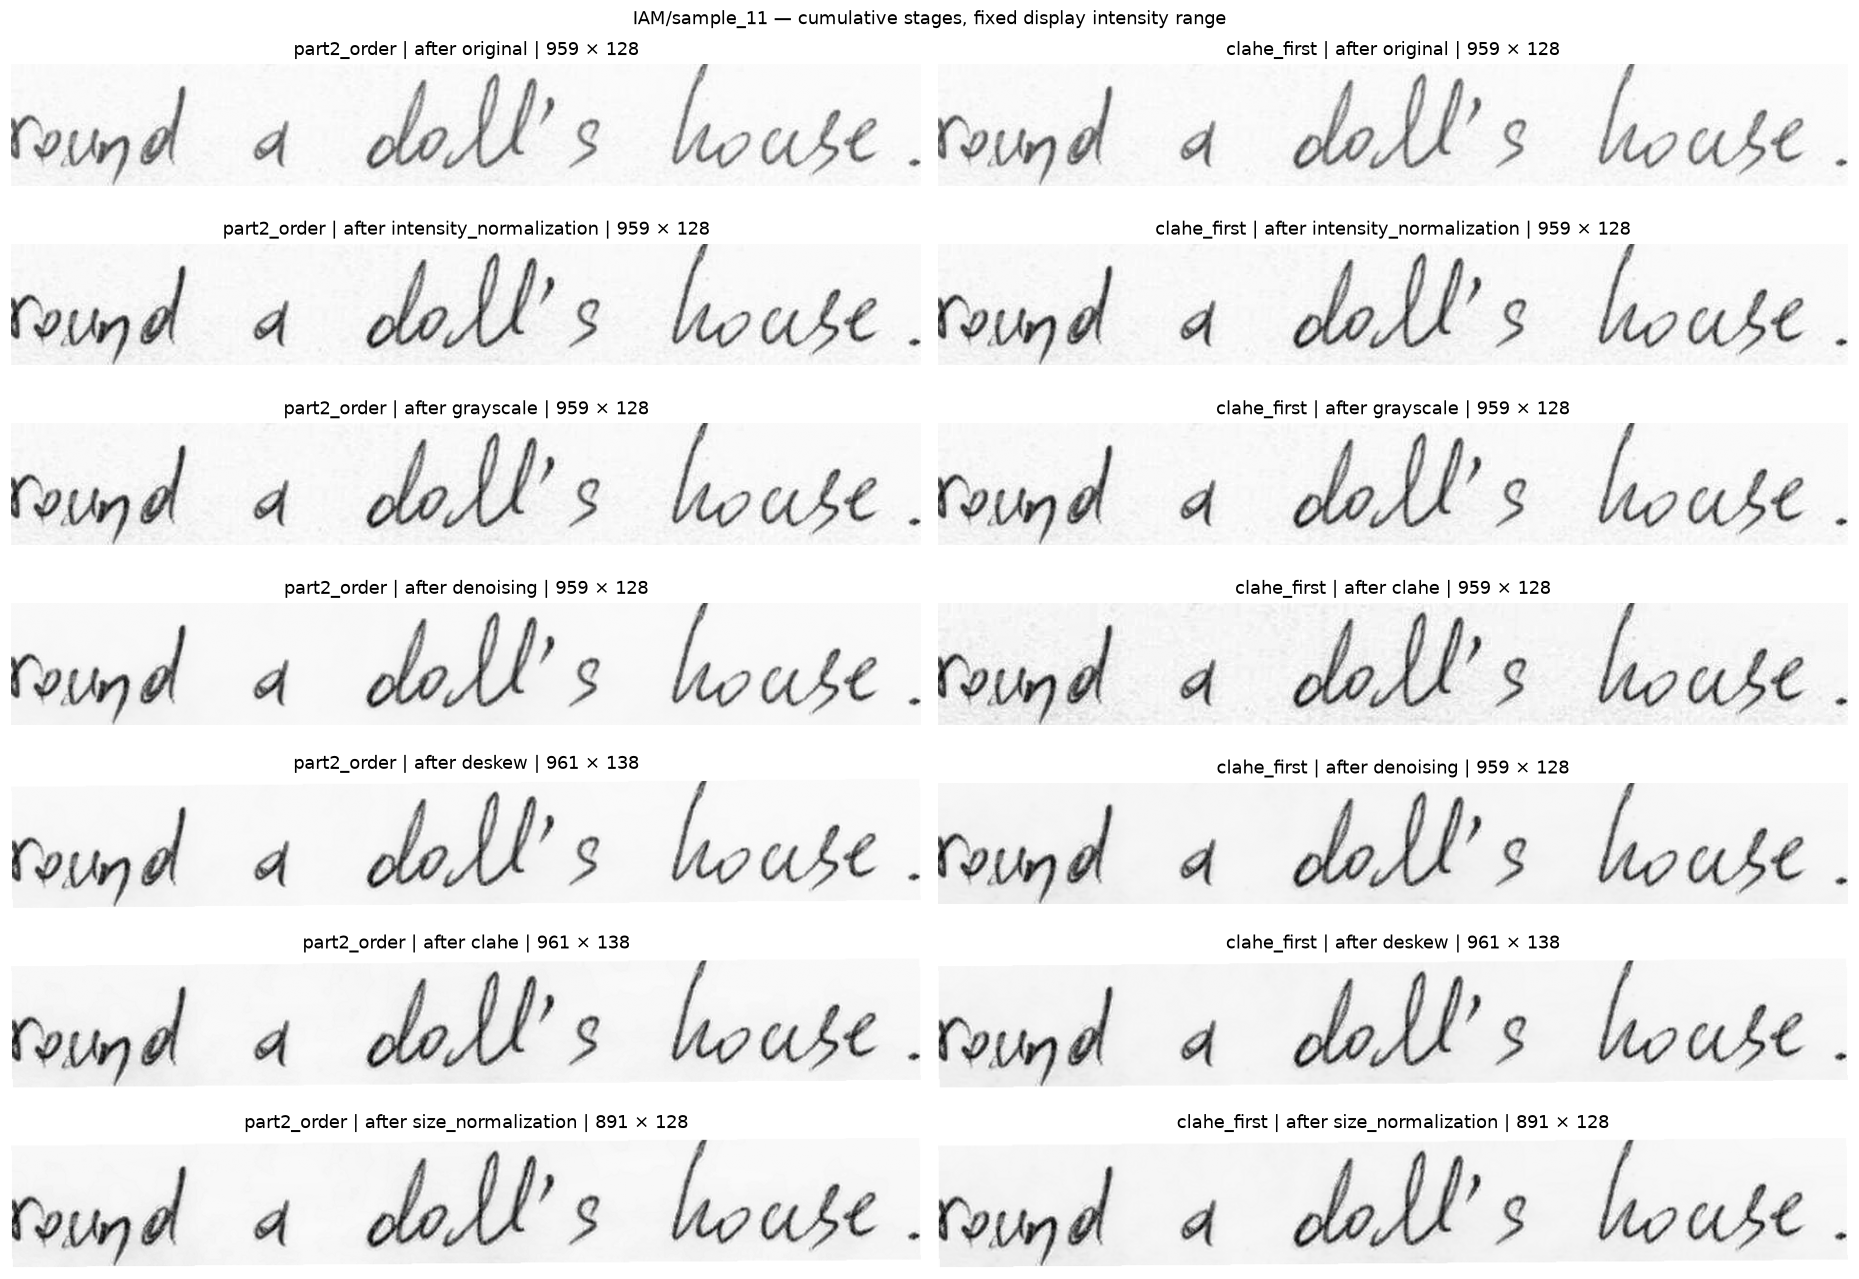

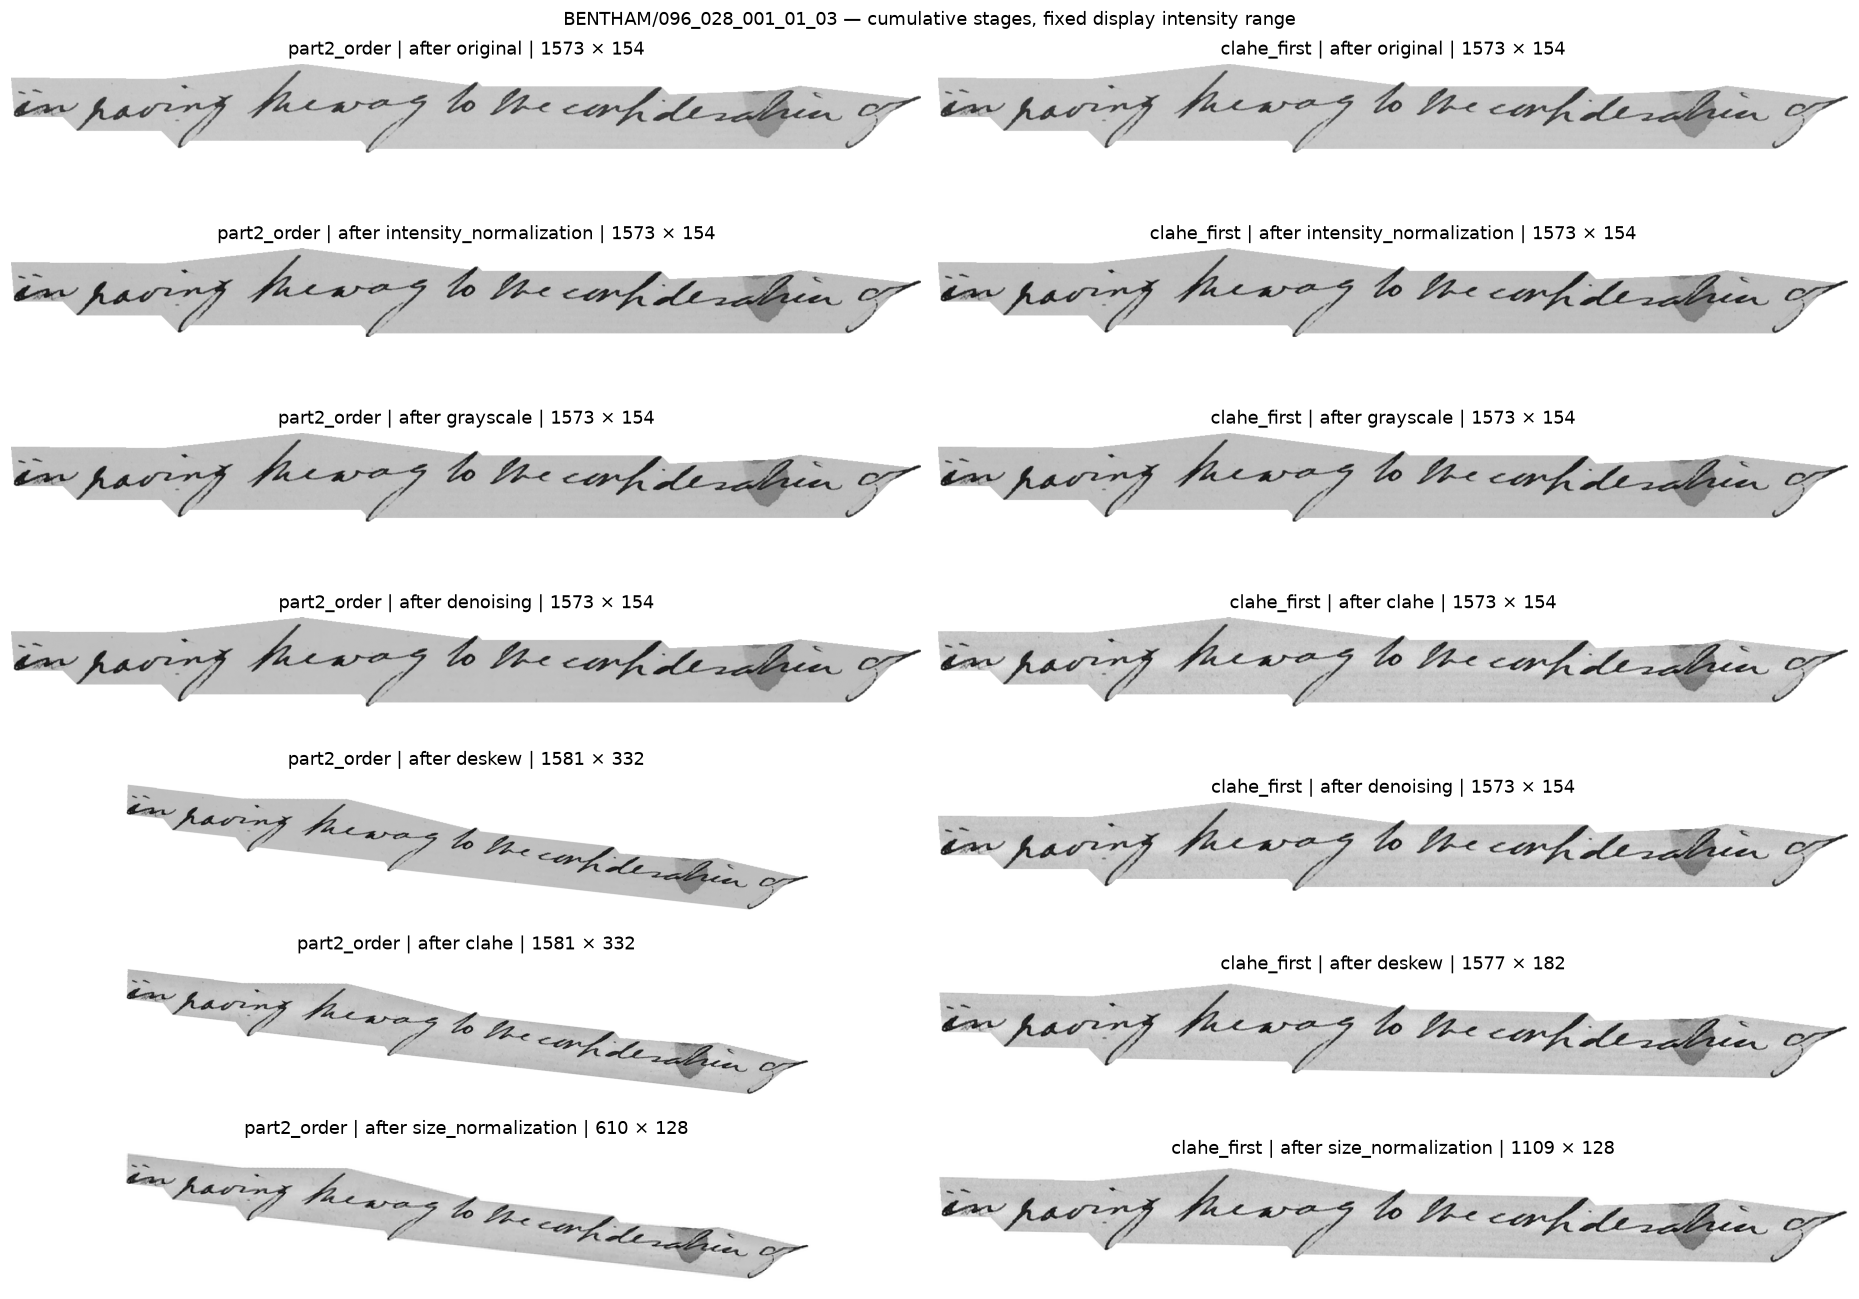

In [6]:
stage_preview_figures = {}
for dataset_name in selected:
    sample = samples_by_dataset[dataset_name][0]
    fig, axes = plt.subplots(7, 2, figsize=(17, 12), squeeze=False)
    for col, order_name in enumerate(ORDERS):
        steps = pipelines_by_dataset[dataset_name][order_name].steps
        for i in range(7):
            image = PreprocessingPipeline(steps[:i])(sample["image"])
            stage = "original" if i == 0 else ORDERS[order_name][i-1]
            axes[i, col].imshow(image, cmap="gray", vmin=0, vmax=255)
            axes[i, col].set_title(f"{order_name} | after {stage} | {image.width} × {image.height}")
            axes[i, col].axis("off")
    fig.suptitle(f"{dataset_name.upper()}/{sample['id']} — cumulative stages, fixed display intensity range")
    fig.tight_layout()
    stage_preview_figures[dataset_name] = fig
    plt.show()

## Recognition and saved artifacts

Restore the exact Part 2 protocol and verify dataset/sample fingerprints and model identity. Reuse its baseline and combined predictions only after checking the full signed identity; record their source paths and source configuration names. Generate fresh clahe_first predictions on both datasets. Model loading and warm-up are excluded from timing; reused timing values remain descriptive.

Write protocol, frozen ordered configurations and samples before inference under results/test/experiment_a_part_3/<UTC-study-id>/. Save every batch so the inference cell can resume in the same kernel. Do not change settings based on these test results.

In [8]:
if "run_dir" not in globals() or "results/test/experiment_a_part_3" not in run_dir.as_posix():
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run_dir = ROOT / "results/test/experiment_a_part_3" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    metadata = {
        "experiment": "Experiment A Part 3: fixed order comparison", "phase": "final_test", "split": SPLIT,
        "sample_count_per_dataset": SAMPLE_COUNT, "seed": SEED, "batch_size": BATCH_SIZE,
        "sample_indices": indices_by_dataset, "part1_reference": str(PART1.relative_to(ROOT)), "part2_reference": str(PART2.relative_to(ROOT)),
        "selection": "dataset-specific active parameters frozen in Part 1 from validation CER then WER",
        "validation_selections": reference["validation_selections"],
        "selection_studies": reference["selection_studies"],
        "preprocessing": frozen_config, "preprocessing_orders": {name: list(order) for name, order in ORDERS.items()},
        "frozen_configuration_sha256": config_digest, "datasets": reference["datasets"],
        "bentham_archive_sha256": ARCHIVES,
        "normalization": "collapse whitespace; retain case and punctuation",
        "input_adaptation": "RGBA white composite; preserve L/RGB",
        "python": platform.python_version(), "platform": platform.platform(),
        "versions": {p: version(p) for p in ("torch", "transformers", "datasets", "huggingface-hub",
            "jiwer", "numpy", "Pillow", "opencv-python-headless", "pandas", "matplotlib")},
    }
    sample_info.to_csv(run_dir / "samples.csv", index=False)
    pd.DataFrame(parameter_rows).to_csv(run_dir / "frozen_parameters.csv", index=False)
    (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
    (run_dir / "status.json").write_text(json.dumps({"status": "running", "expected_dataset_configuration_pairs": 6}))
saved_protocol = json.loads((run_dir / "metadata.json").read_text())
assert saved_protocol["frozen_configuration_sha256"] == config_digest
assert saved_protocol["sample_indices"] == indices_by_dataset
assert config_digest == hashlib.sha256(json.dumps({ds: {name: pipe.to_config() for name, pipe in pipes.items()}
    for ds, pipes in pipelines_by_dataset.items()}, sort_keys=True).encode()).hexdigest()
if "model" not in globals():
    model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION, device=DEVICE, generation_kwargs=GENERATION)
    _ = model.predict(samples_by_dataset["iam"][0]["image"])
assert json.loads(json.dumps(model.to_config())) == reference["model"]
metadata["model"] = model.to_config()
summaries = []
for name in pipeline_names:
    for dataset_name, dataset in selected.items():
        pipeline = pipelines_by_dataset[dataset_name][name]
        folder = run_dir / dataset_name / name
        if name in ("baseline", "part2_order") and not folder.exists():
            source_name = "baseline" if name == "baseline" else "combined"
            source = PART2 / dataset_name / source_name
            identity = json.loads((source / "identity.json").read_text())
            assert identity["dataset_fingerprint"] == dataset._fingerprint and identity["count"] == SAMPLE_COUNT
            assert identity["transform"] == json.loads(json.dumps(pipeline.to_config())) and identity["batch_size"] == BATCH_SIZE
            assert identity["model"] == json.loads(json.dumps(model.to_config()))
            assert identity["normalization"] == "collapse whitespace; preserve case/punctuation"
            assert identity["input_adaptation"] == "RGBA white composite; preserve L/RGB"
            shutil.copytree(source, folder)
            metadata.setdefault("reused_prediction_sources", {})[dataset_name + "/" + name] = str(source.relative_to(ROOT))
        (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
        result = evaluate(dataset, dataset_name, model, name, pipeline, run_dir, BATCH_SIZE)
        summaries.append(result)
        pd.DataFrame(summaries).to_csv(run_dir / "partial_summary.csv", index=False)
        print(result, flush=True)
summary = pd.DataFrame(summaries)
assert len(summary) == 6 and summary.sample_count.eq(250).all()
for metric in ("cer", "wer"):
    base = summary[summary.configuration == "baseline"].set_index("dataset")[metric]
    summary[f"{metric}_change_pp"] = 100 * (summary[metric] - summary.dataset.map(base))
    summary[f"{metric}_relative_change_pct"] = 100 * (summary[metric] / summary.dataset.map(base) - 1)
for metric in ("cer", "wer"):
    previous = summary[summary.configuration == "part2_order"].set_index("dataset")[metric]
    summary[f"{metric}_change_vs_part2_pp"] = 100 * (summary[metric] - summary.dataset.map(previous))
    summary[f"{metric}_relative_change_vs_part2_pct"] = 100 * (summary[metric] / summary.dataset.map(previous) - 1)
summary["total_seconds"] = summary.preprocessing_seconds + summary.inference_seconds
summary["seconds_per_line"] = summary.total_seconds / summary.sample_count
frames = []
for dataset_name in selected:
    for name in pipeline_names:
        frame = pd.read_csv(run_dir / dataset_name / name / "predictions.csv", keep_default_na=False)
        assert frame.sample_id.tolist() == [s["id"] for s in samples_by_dataset[dataset_name]]
        frames.append(frame.assign(dataset=dataset_name, configuration=name))
predictions = pd.concat(frames, ignore_index=True)
summary.to_csv(run_dir / "summary.csv", index=False)
predictions.to_csv(run_dir / "predictions.csv", index=False)
for dataset_name, fig in stage_preview_figures.items():
    fig.savefig(run_dir / f"{dataset_name}_preprocessing_stages.png", bbox_inches="tight")
(run_dir / "status.json").write_text(json.dumps({"status": "inference_complete", "completed_dataset_configuration_pairs": 6}))
print("Saved:", run_dir)
display(summary)

{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 250, 'cer': 0.04776260009420631, 'wer': 0.10812023328847016, 'preprocessing_seconds': 0.007902452001872007, 'inference_seconds': 75.54761058299846}
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 250, 'cer': 0.16121244635193133, 'wer': 0.428854734754586, 'preprocessing_seconds': 0.09649438100677799, 'inference_seconds': 70.62097046100462}
{'dataset': 'iam', 'configuration': 'part2_order', 'sample_count': 250, 'cer': 0.04983513895430994, 'wer': 0.11395244504262, 'preprocessing_seconds': 16.812962707992483, 'inference_seconds': 76.37208454299434}
{'dataset': 'bentham', 'configuration': 'part2_order', 'sample_count': 250, 'cer': 0.15236051502145923, 'wer': 0.4189390183440754, 'preprocessing_seconds': 24.24777891299709, 'inference_seconds': 70.18671420699502}
iam/clahe_first: 8/250
iam/clahe_first: 80/250
iam/clahe_first: 160/250
iam/clahe_first: 240/250
iam/clahe_first: 250/250
{'dataset': 'iam', 'configur

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_change_pp,cer_relative_change_pct,wer_change_pp,wer_relative_change_pct,cer_change_vs_part2_pp,cer_relative_change_vs_part2_pct,wer_change_vs_part2_pp,wer_relative_change_vs_part2_pct,total_seconds,seconds_per_line
0,iam,baseline,250,0.047763,0.108120,0.007902,75.547611,0.000000,0.000000,0.000000,0.000000,-0.207254,-4.158790,-0.583221,-5.118110,75.555513,0.302222
1,bentham,baseline,250,0.161212,0.428855,0.096494,70.620970,0.000000,0.000000,0.000000,0.000000,0.885193,5.809859,0.991572,2.366864,70.717465,0.282870
2,iam,part2_order,250,0.049835,0.113952,16.812963,76.372085,0.207254,4.339250,0.583221,5.394191,0.000000,0.000000,0.000000,0.000000,93.185047,0.372740
3,bentham,part2_order,250,0.152361,0.418939,24.247779,70.186714,-0.885193,-5.490849,-0.991572,-2.312139,0.000000,0.000000,0.000000,0.000000,94.434493,0.377738
4,iam,clahe_first,250,0.049081,0.113055,17.508169,76.160779,0.131889,2.761341,0.493495,4.564315,-0.075365,-1.512287,-0.089726,-0.787402,93.668948,0.374676
5,bentham,clahe_first,250,0.151377,0.411006,25.614348,72.312907,-0.983548,-6.100943,-1.784829,-4.161850,-0.098355,-0.645540,-0.793257,-1.893491,97.927255,0.391709


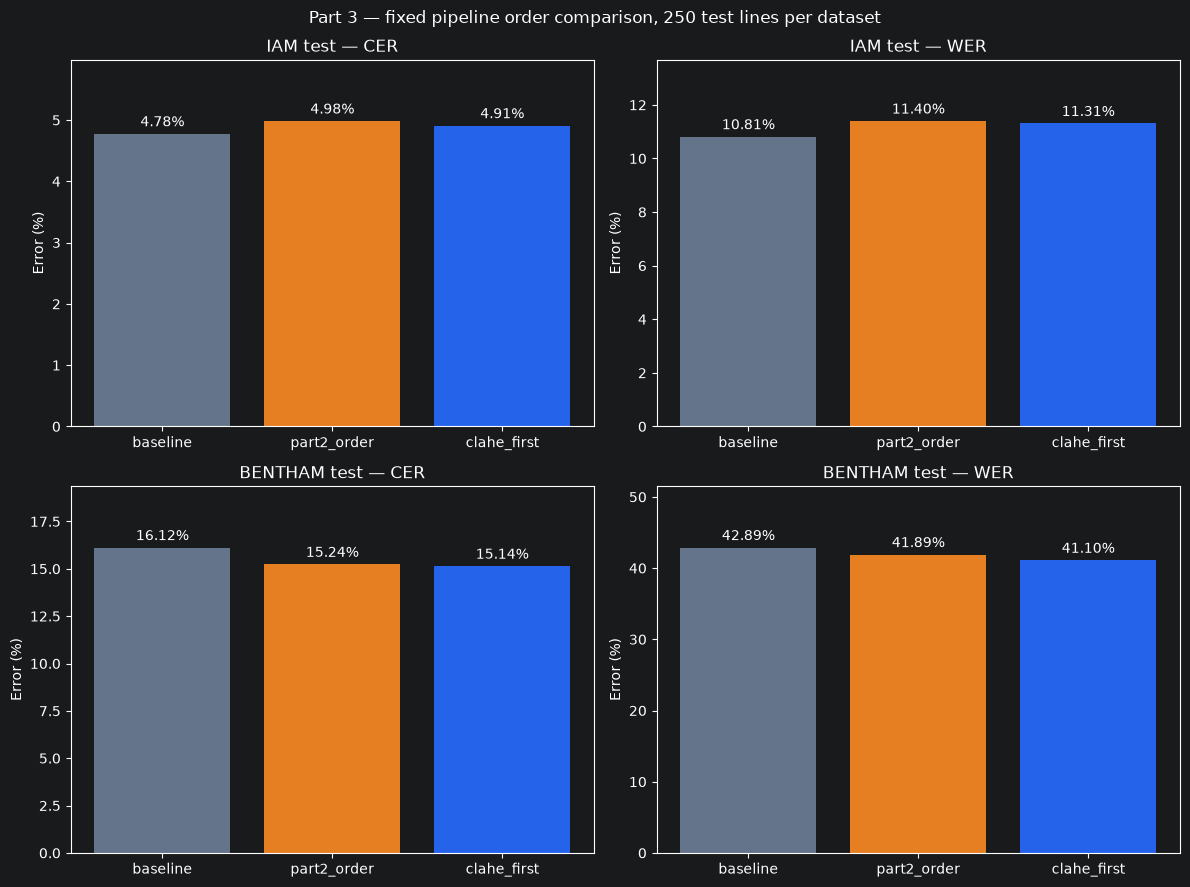

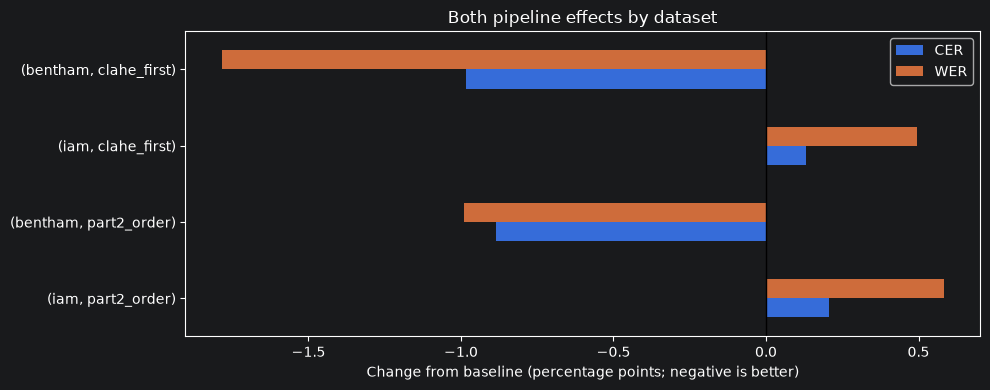

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, dataset_name in enumerate(selected):
    current = summary[summary.dataset == dataset_name].set_index("configuration").loc[pipeline_names]
    for col, metric in enumerate(("cer", "wer")):
        values = 100 * current[metric]
        bars = axes[row, col].bar(current.index, values, color=["#64748b", "#e67e22", "#2563eb"])
        axes[row, col].bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=3)
        axes[row, col].set(title=f"{dataset_name.upper()} test — {metric.upper()}", ylabel="Error (%)")
        axes[row, col].margins(y=.2)
fig.suptitle("Part 3 — fixed pipeline order comparison, 250 test lines per dataset")
fig.tight_layout()
fig.savefig(run_dir / "corpus_error_rates.png", bbox_inches="tight")
plt.show()
changes = summary[summary.configuration != "baseline"].set_index(["dataset", "configuration"])[["cer_change_pp", "wer_change_pp"]]
ax = changes.rename(columns={"cer_change_pp": "CER", "wer_change_pp": "WER"}).plot.barh(figsize=(10, 4))
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Change from baseline (percentage points; negative is better)", ylabel="", title="Both pipeline effects by dataset")
plt.tight_layout()
plt.savefig(run_dir / "corpus_changes.png", bbox_inches="tight")
plt.show()

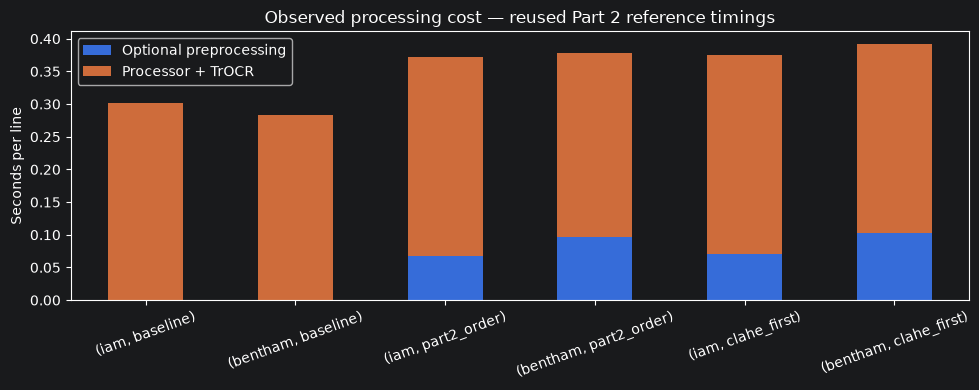

In [10]:
timing = summary.set_index(["dataset", "configuration"])[["preprocessing_seconds", "inference_seconds"]].div(
    summary.set_index(["dataset", "configuration"])["sample_count"], axis=0)
ax = timing.rename(columns={"preprocessing_seconds": "Optional preprocessing",
    "inference_seconds": "Processor + TrOCR"}).plot.bar(stacked=True, figsize=(10, 4), rot=20)
ax.set(xlabel="", ylabel="Seconds per line", title="Observed processing cost — reused Part 2 reference timings")
plt.tight_layout()
plt.savefig(run_dir / "processing_time.png", bbox_inches="tight")
plt.show()

## Where does preprocessing help or hurt?

The next plots pair each line with its own baseline. The scatter diagonal means equal CER. The count chart uses per-line CER to count improved, unchanged, and worsened lines; these counts are diagnostics, not corpus metrics or a statistical significance test. A technique can help many short lines and still worsen corpus CER if it damages longer lines.

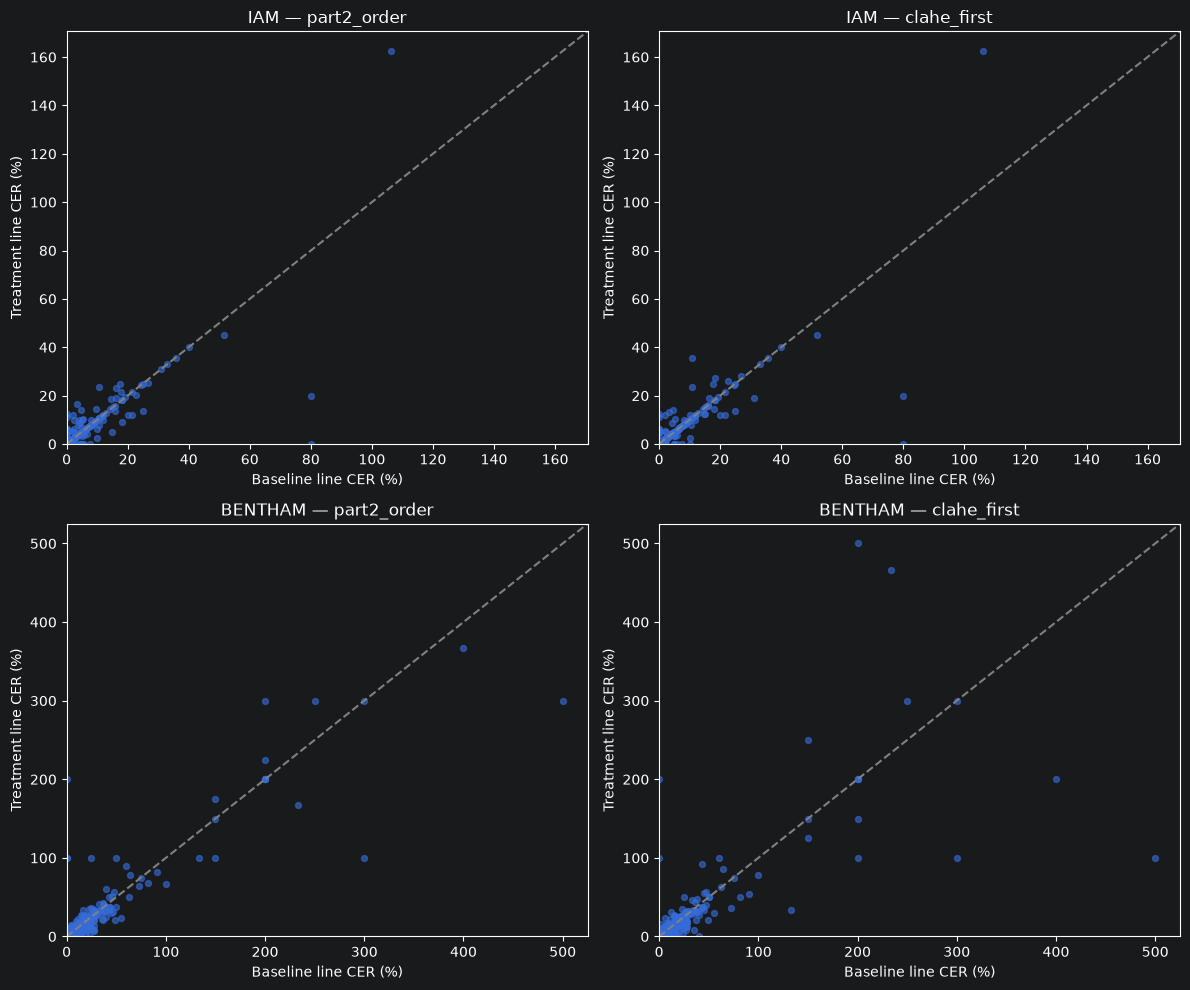

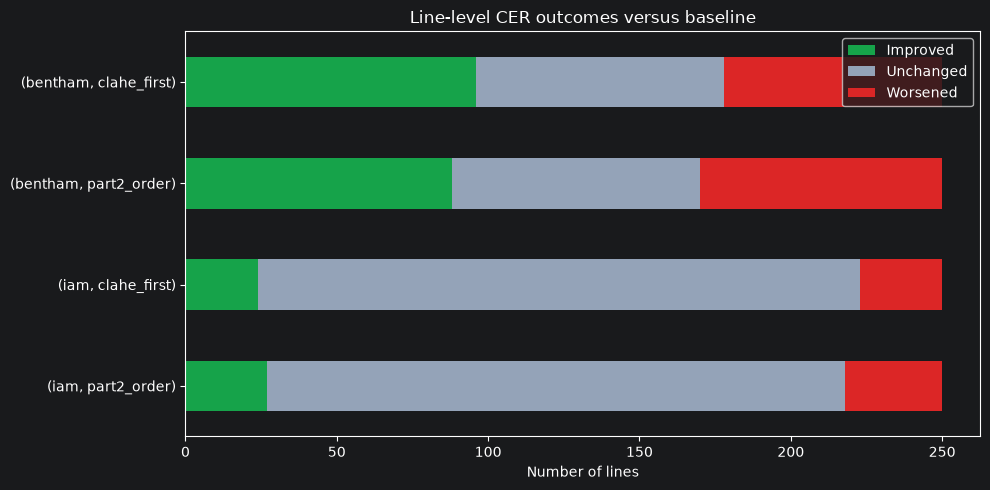

Improved  Unchanged  Worsened
dataset configuration                               
iam     part2_order          27        191        32
        clahe_first          24        199        27
bentham part2_order          88         82        80
        clahe_first          96         82        72

In [11]:
paired_by_dataset, outcome_rows = {}, []
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for row, dataset_name in enumerate(selected):
    paired = predictions[predictions.dataset == dataset_name].pivot(index="sample_id", columns="configuration", values="cer")
    paired_by_dataset[dataset_name] = paired
    for col, name in enumerate(("part2_order", "clahe_first")):
        ax = axes[row, col]
        x, y = 100 * paired["baseline"], 100 * paired[name]
        limit = max(float(x.max()), float(y.max()), 1) * 1.05
        ax.scatter(x, y, alpha=.6, s=18)
        ax.plot([0, limit], [0, limit], "--", color="gray")
        ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Baseline line CER (%)", ylabel="Treatment line CER (%)",
            title=f"{dataset_name.upper()} — {name}")
        delta = paired[name] - paired["baseline"]
        same = np.isclose(delta, 0, atol=1e-12, rtol=0)
        outcome_rows.append({"dataset": dataset_name, "configuration": name,
            "Improved": int(((delta < 0) & ~same).sum()), "Unchanged": int(same.sum()),
            "Worsened": int(((delta > 0) & ~same).sum())})
fig.tight_layout()
fig.savefig(run_dir / "paired_line_cer.png", bbox_inches="tight")
plt.show()
outcomes = pd.DataFrame(outcome_rows).set_index(["dataset", "configuration"])
ax = outcomes.plot.barh(stacked=True, color=["#16a34a", "#94a3b8", "#dc2626"], figsize=(10, 5))
ax.set(xlabel="Number of lines", ylabel="", title="Line-level CER outcomes versus baseline")
plt.tight_layout()
plt.savefig(run_dir / "line_outcomes.png", bbox_inches="tight")
plt.show()
outcomes.to_csv(run_dir / "line_outcomes.csv")
display(outcomes)

iam/sample_798 | CER change -80.00 pp
Reference: darkness .
Baseline: at a business .
Part 2: darkness .
CLAHE first: darkness .
iam/sample_1669 | CER change +56.25 pp
Reference: trans-economic .
Baseline: transuming a recession in C.
Part 2: transuming in a Belgian crisis i. c.
CLAHE first: transuming in a Belgian crisis i. c.


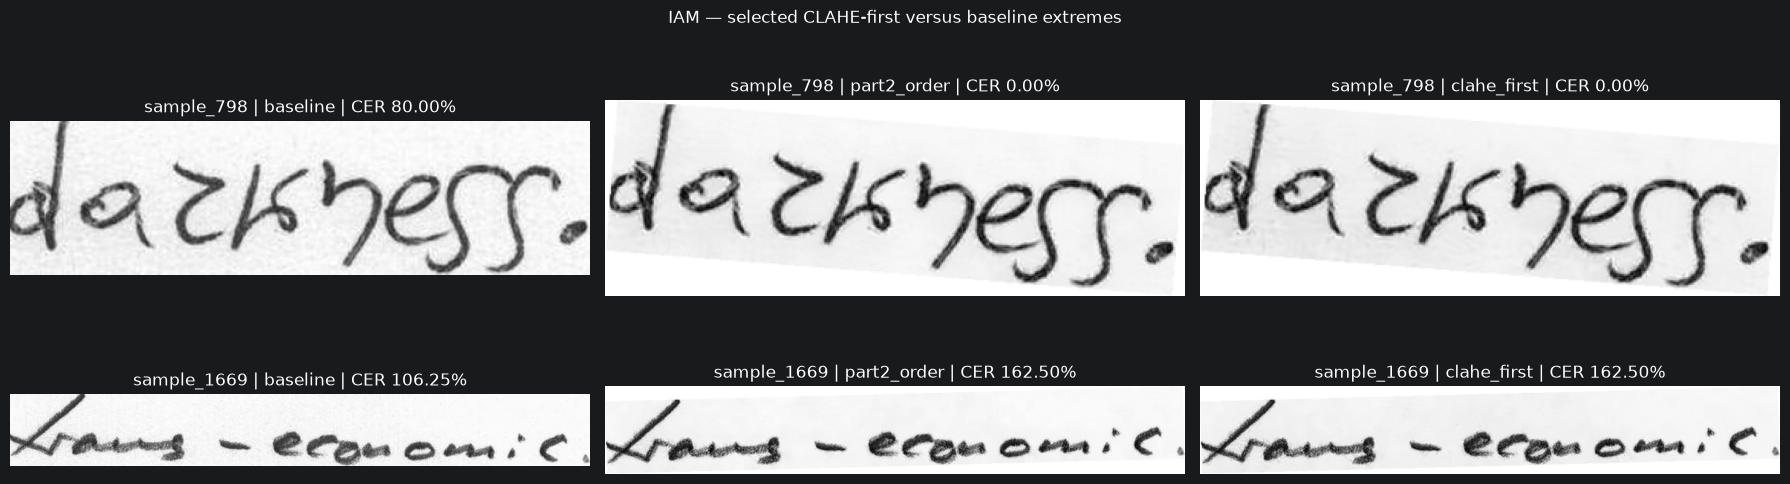

bentham/115_077_002_01_01 | CER change -400.00 pp
Reference: 9 
Baseline: ailey
Part 2: 0 1
CLAHE first: 0
bentham/071_163_004_02_01 | CER change +300.00 pp
Reference: C 
Baseline: c.
Part 2: cis
CLAHE first: cipic


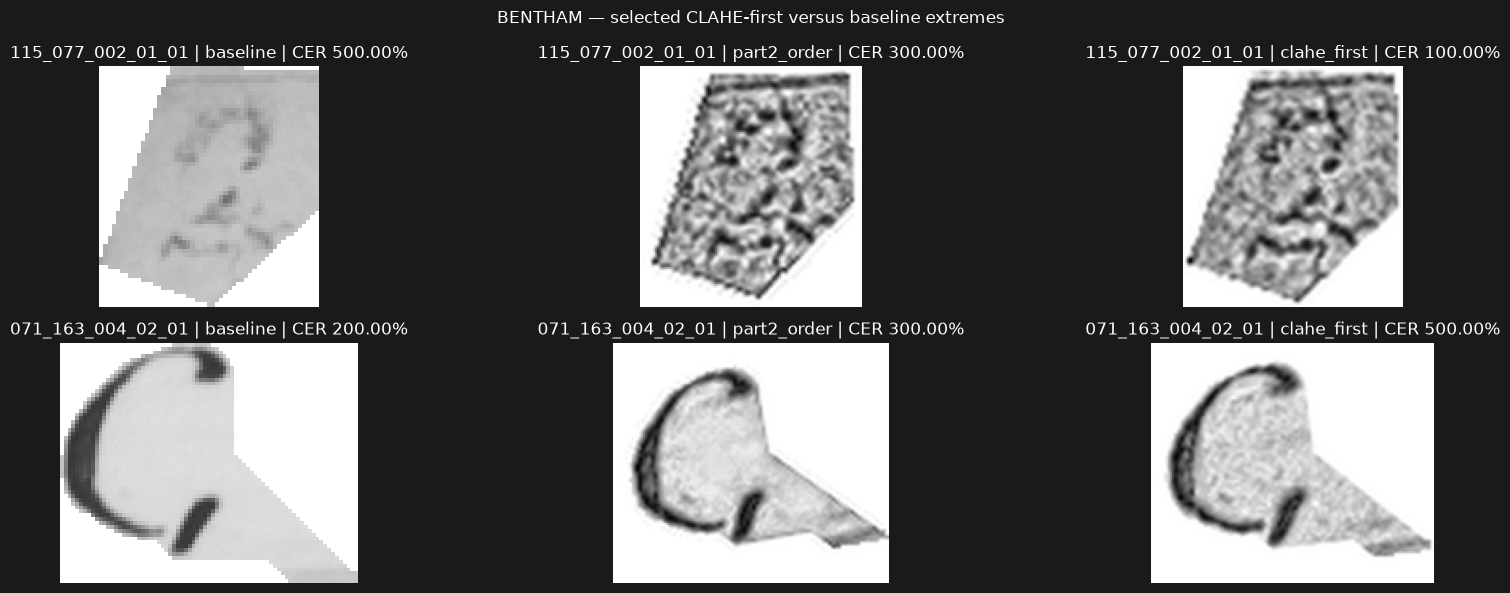

In [12]:
# Deliberately selected CER-change extremes, not representative examples.
for dataset_name in selected:
    paired = paired_by_dataset[dataset_name]
    sample_by_id = {s["id"]: s for s in samples_by_dataset[dataset_name]}
    lookup = predictions[predictions.dataset == dataset_name].set_index(["sample_id", "configuration"])
    delta = paired["clahe_first"] - paired["baseline"]
    example_ids = list(dict.fromkeys([delta.idxmin(), delta.idxmax()]))
    fig, axes = plt.subplots(len(example_ids), 3, figsize=(18, 3 * len(example_ids)), squeeze=False)
    for row, sample_id in enumerate(example_ids):
        sample = sample_by_id[sample_id]
        for col, name in enumerate(pipeline_names):
            image = pipelines_by_dataset[dataset_name][name](sample["image"])
            axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255)
            axes[row, col].set_title(f"{sample_id} | {name} | CER {100 * paired.loc[sample_id, name]:.2f}%")
            axes[row, col].axis("off")
        print(f"{dataset_name}/{sample_id} | CER change {100 * delta.loc[sample_id]:+.2f} pp")
        print("Reference:", sample["ground_truth"])
        print("Baseline:", lookup.loc[(sample_id, "baseline"), "prediction"])
        print("Part 2:", lookup.loc[(sample_id, "part2_order"), "prediction"])
        print("CLAHE first:", lookup.loc[(sample_id, "clahe_first"), "prediction"])
    fig.suptitle(f"{dataset_name.upper()} — selected CLAHE-first versus baseline extremes")
    fig.tight_layout()
    fig.savefig(run_dir / f"{dataset_name}_examples_clahe_first.png", bbox_inches="tight")
    plt.show()

## Direct comparison with Part 2

Here the comparator is the previous pipeline order rather than baseline. Report both corpus CER/WER changes and paired line-level outcomes. The examples show the minimum and maximum line CER changes; they are selected extremes, not representative samples.

,cer_change_vs_part2_pp,wer_change_vs_part2_pp
dataset,,
iam,-0.075365,-0.089726
bentham,-0.098355,-0.793257


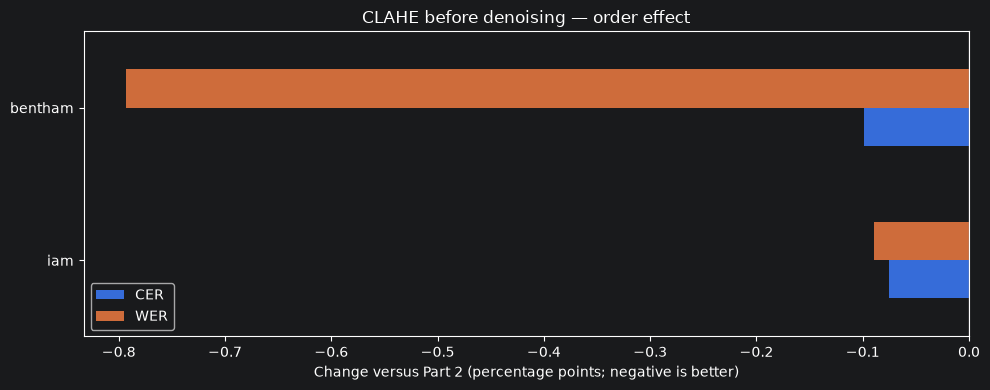

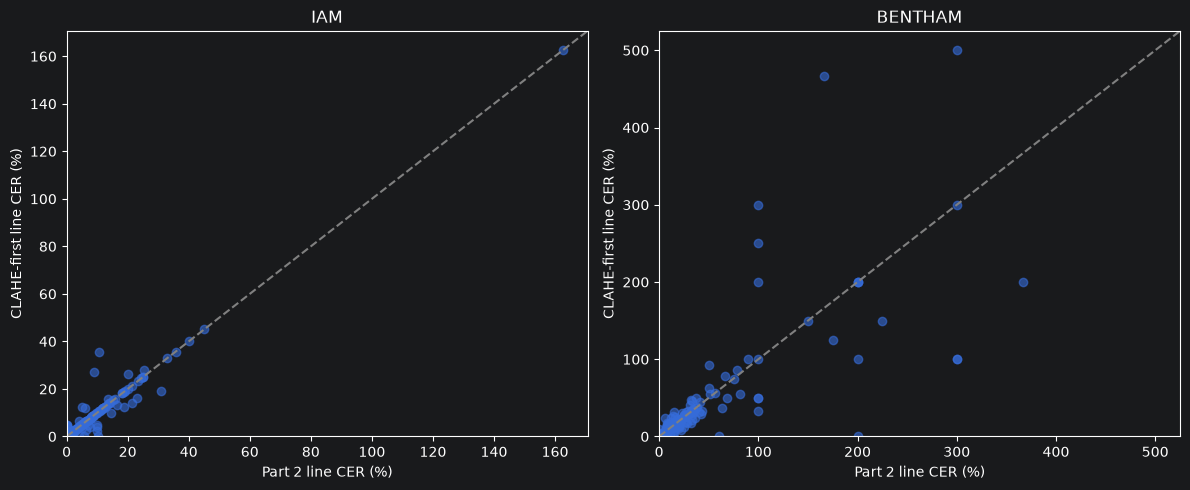

,improved,unchanged,worsened
dataset,,,
iam,18,218,14
bentham,61,137,52


iam/sample_2183 | change versus Part 2: -11.905 pp
Reference: to all kin' o' boats , wid d'ose big , big
baseline: to all trial of Scouts , which chose big , big
part2_order: to all trial of Scouts , which chose big , big
clahe_first: to all kind of boats , which close biz , big
iam/sample_2244 | change versus Part 2: +25.000 pp
Reference: water in her . I wouldn't be
baseline: wrote in her . I wouldn't be
part2_order: wrote in her . I wouldn't be
clahe_first: wrote in her . Iwocelda the


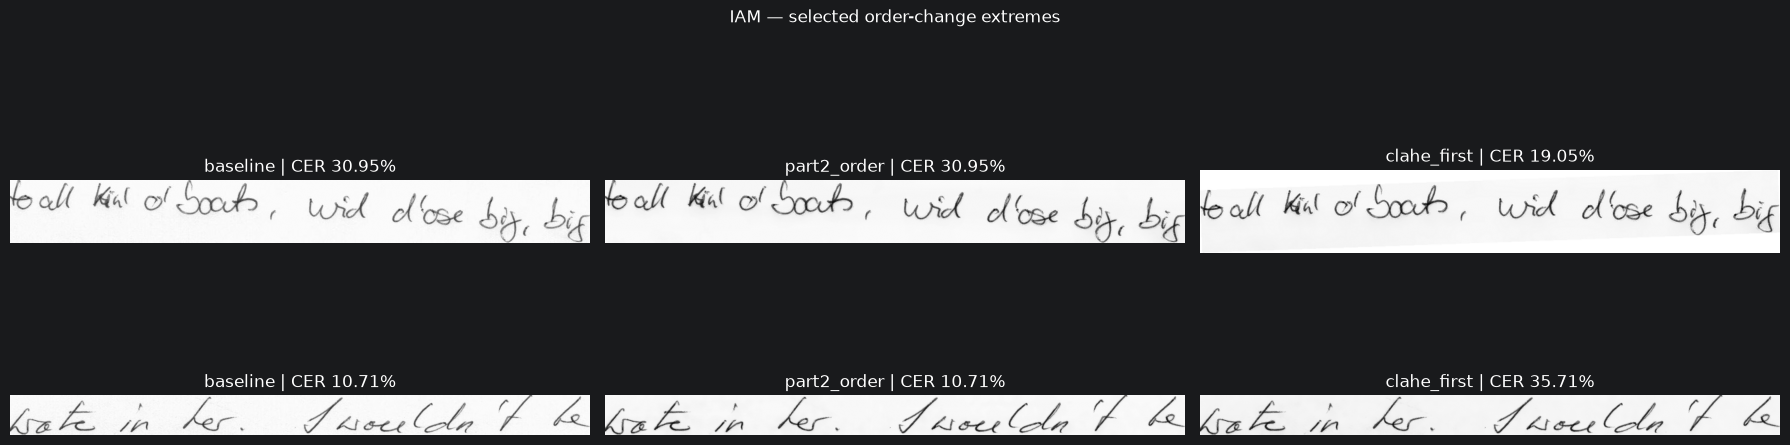

bentham/035_327_001_02_23 | change versus Part 2: -200.000 pp
Reference: 1 
baseline: 1
part2_order: 1 .
clahe_first: 1
bentham/071_030_001_04_25 | change versus Part 2: +300.000 pp
Reference: (A) 
baseline: pick up
part2_order: ple A
clahe_first: pillarship the


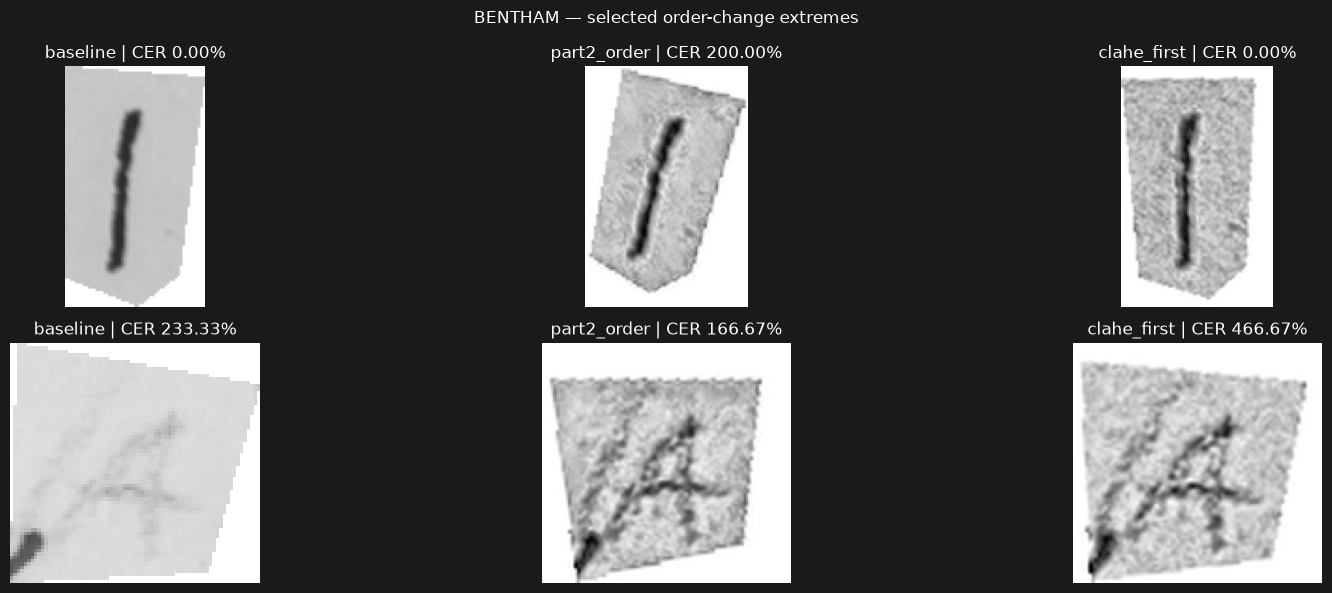

In [13]:
order_changes = summary[summary.configuration == "clahe_first"].set_index("dataset")[
    ["cer_change_vs_part2_pp", "wer_change_vs_part2_pp"]]
display(order_changes)
ax = order_changes.rename(columns={"cer_change_vs_part2_pp": "CER", "wer_change_vs_part2_pp": "WER"}).plot.barh(figsize=(10, 4))
ax.axvline(0, color="gray", linewidth=1)
ax.set(xlabel="Change versus Part 2 (percentage points; negative is better)", ylabel="", title="CLAHE before denoising — order effect")
plt.tight_layout()
plt.savefig(run_dir / "changes_vs_part2.png", bbox_inches="tight")
plt.show()
order_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, dataset_name in zip(axes, selected):
    paired = paired_by_dataset[dataset_name]
    delta = paired["clahe_first"] - paired["part2_order"]
    same = np.isclose(delta, 0, atol=1e-12, rtol=0)
    order_rows.append({"dataset": dataset_name, "improved": int(((delta < 0) & ~same).sum()),
        "unchanged": int(same.sum()), "worsened": int(((delta > 0) & ~same).sum())})
    x, y = 100 * paired["part2_order"], 100 * paired["clahe_first"]
    limit = max(float(x.max()), float(y.max()), 1) * 1.05
    ax.scatter(x, y, alpha=.6)
    ax.plot([0, limit], [0, limit], "--", color="gray")
    ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Part 2 line CER (%)",
        ylabel="CLAHE-first line CER (%)", title=dataset_name.upper())
fig.tight_layout()
fig.savefig(run_dir / "paired_cer_vs_part2.png", bbox_inches="tight")
plt.show()
order_outcomes = pd.DataFrame(order_rows).set_index("dataset")
order_outcomes.to_csv(run_dir / "order_outcomes.csv")
display(order_outcomes)
for dataset_name in selected:
    paired = paired_by_dataset[dataset_name]
    delta = paired["clahe_first"] - paired["part2_order"]
    example_ids = list(dict.fromkeys([delta.idxmin(), delta.idxmax()]))
    sample_by_id = {s["id"]: s for s in samples_by_dataset[dataset_name]}
    lookup = predictions[predictions.dataset == dataset_name].set_index(["sample_id", "configuration"])
    fig, axes = plt.subplots(len(example_ids), 3, figsize=(18, 3 * len(example_ids)), squeeze=False)
    for row, sample_id in enumerate(example_ids):
        sample = sample_by_id[sample_id]
        print(f"{dataset_name}/{sample_id} | change versus Part 2: {100 * delta.loc[sample_id]:+.3f} pp")
        print("Reference:", sample["ground_truth"])
        for col, name in enumerate(pipeline_names):
            axes[row, col].imshow(pipelines_by_dataset[dataset_name][name](sample["image"]), cmap="gray", vmin=0, vmax=255)
            axes[row, col].set_title(f"{name} | CER {100 * paired.loc[sample_id, name]:.2f}%")
            axes[row, col].axis("off")
            print(name + ":", lookup.loc[(sample_id, name), "prediction"])
    fig.suptitle(f"{dataset_name.upper()} — selected order-change extremes")
    fig.tight_layout()
    fig.savefig(run_dir / f"{dataset_name}_examples_order_comparison.png", bbox_inches="tight")
    plt.show()

## Final IAM and Bentham comparison

The final tables report baseline, Part 2 order and CLAHE-first CER/WER separately for each dataset and side by side. Changes versus Part 2 are clahe_first minus part2_order; negative values favor the reordered pipeline. Baseline comparisons show whether either pipeline helps relative to untreated inputs.

This fixed order comparison does not prove an optimal order, statistical significance, or that a visual change in background texture caused a recognition change. CLAHE also moves before deskew and may affect angle estimation. Selected examples are diagnostic extremes. Mandatory TrOCR resizing follows both optional pipelines. Timing includes reused Part 2 reference values and is descriptive.

Parameters and samples stay fixed; these test results are not used to tune further settings. Parts 1 and 2 are unchanged.

In [14]:
assert order_outcomes.sum(axis=1).eq(250).all()
assert len(predictions) == 1500
assert json.loads((run_dir / "metadata.json").read_text())["frozen_configuration_sha256"] == config_digest
for (dataset_name, name), rows in predictions.groupby(["dataset", "configuration"]):
    assert len(rows) == 250
    measured = corpus_metrics(rows.ground_truth.tolist(), rows.prediction.tolist())
    recorded = summary[(summary.dataset == dataset_name) & (summary.configuration == name)].iloc[0]
    assert all(np.isclose(measured[metric], recorded[metric], atol=1e-12, rtol=0) for metric in ("cer", "wer"))
assert outcomes.sum(axis=1).eq(250).all()
final_results = summary.assign(cer_pct=100 * summary.cer, wer_pct=100 * summary.wer)
for dataset_name in ("iam", "bentham"):
    print(f"{dataset_name.upper()} — FINAL TEST RESULTS (250 lines)")
    display(final_results[final_results.dataset == dataset_name][
        ["configuration", "sample_count", "cer_pct", "wer_pct", "cer_change_pp", "wer_change_pp", "cer_change_vs_part2_pp", "wer_change_vs_part2_pp"]].round(4))
both_datasets = final_results.pivot(index="configuration", columns="dataset", values=["cer_pct", "wer_pct"]).reindex(pipeline_names)
print("Both datasets — corpus error rates (%)")
display(both_datasets.round(4))
both_datasets.to_csv(run_dir / "final_results_both_datasets.csv")
part1_summary = pd.read_csv(PART1 / "summary.csv")
individual_and_combined = pd.concat([part1_summary.assign(experiment="Part 1"),
    summary[summary.configuration != "baseline"].assign(experiment="Part 3")], ignore_index=True)
comparison = individual_and_combined.assign(cer_pct=lambda x: 100*x.cer, wer_pct=lambda x: 100*x.wer).pivot(
    index="configuration", columns="dataset", values=["cer_pct", "wer_pct"])
print("Individual techniques and both combined orders — same fixed test subsets")
display(comparison.round(4))
comparison.to_csv(run_dir / "all_parts_comparison.csv")
(run_dir / "status.json").write_text(json.dumps({"status": "complete", "split": "test",
    "samples_per_dataset": 250, "completed_dataset_configuration_pairs": 6}, indent=2))
print("Results:", run_dir)

IAM — FINAL TEST RESULTS (250 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp,cer_change_vs_part2_pp,wer_change_vs_part2_pp
0,baseline,250,4.7763,10.8120,0.0000,0.0000,-0.2073,-0.5832
2,part2_order,250,4.9835,11.3952,0.2073,0.5832,0.0000,0.0000
4,clahe_first,250,4.9081,11.3055,0.1319,0.4935,-0.0754,-0.0897


BENTHAM — FINAL TEST RESULTS (250 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp,cer_change_vs_part2_pp,wer_change_vs_part2_pp
1,baseline,250,16.1212,42.8855,0.0000,0.0000,0.8852,0.9916
3,part2_order,250,15.2361,41.8939,-0.8852,-0.9916,0.0000,0.0000
5,clahe_first,250,15.1377,41.1006,-0.9835,-1.7848,-0.0984,-0.7933


Both datasets — corpus error rates (%)


cer_pct          wer_pct         
dataset        bentham     iam  bentham      iam
configuration                                   
baseline       16.1212  4.7763  42.8855  10.8120
part2_order    15.2361  4.9835  41.8939  11.3952
clahe_first    15.1377  4.9081  41.1006  11.3055

Individual techniques and both combined orders — same fixed test subsets


cer_pct          wer_pct         
dataset                  bentham     iam  bentham      iam
configuration                                             
baseline                 16.1212  4.7763  42.8855  10.8120
clahe                    14.7353  4.6538  40.7536  10.8569
clahe_first              15.1377  4.9081  41.1006  11.3055
denoising                16.2375  4.6161  42.5384  10.4980
deskew                   16.9617  4.7668  43.8275  10.7672
grayscale                16.1212  4.7763  42.8855  10.8120
intensity_normalization  15.6563  4.6350  42.4888  10.8120
part2_order              15.2361  4.9835  41.8939  11.3952
size_normalization       16.1570  4.7763  42.7863  10.8120

Results: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/test/experiment_a_part_3/20261112T031732610346Z
